In [1]:
import numpy
import pandas
import seaborn

from matplotlib import pyplot

from fitting import TIMESERIES_TABLE_PATH
from realistic import PARAMS

2026-05-07 12:33:58,878 DEBUG [utils] Logging configured at DEBUG
/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 366 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
2026-05-07 12:33:58,897 DEBUG [utils] Data path initialised at /home/anm1u24/Code/self_lensing_radial_velocity/data


In [2]:
pyplot.rcParams["figure.figsize"] = [12.8, 9.6]

In [3]:
def err(obs, model):
    scale = numpy.abs(obs)
    scale[scale == 0] = 1
    return numpy.abs(obs - model) / scale

In [4]:
params = {
    'a': 'fitted_a',
    'b': 'fitted_b',
    'e': 'fitted_e',
    'periapsis_phase': 'fitted_periapsis_phase',
    'Macc': 'fitted_Macc',
    'Porb': 'fitted_porb',
    'tau_eff': 'fitted_tau_eff',
}

In [5]:
results = pandas.read_pickle(TIMESERIES_TABLE_PATH)

In [6]:
results

,realistic_id,realistic_path,pristine_idx,pristine_id,pristine_rv_path,photometry_path,a,e,periapsis_phase,Macc,...,b_max,fitted_a,fitted_b,fitted_b_max,fitted_i,fitted_Macc,fitted_e,fitted_periapsis_phase,fitted_porb,fitted_tau_eff
0,03009e06-6226-5c32-8d9f-69f1f1d0138d,/home/anm1u24/Code/self_lensing_radial_velocit...,9153,e443ad9f-3ee4-44b5-8812-0e038444b607,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,82.274687,0.564271,2.068143,25.239652,...,9.348680155785338,84.96102700738666,0.2760542049795193,9.344538791431464,1.5707678994922436,25.011939130050205,0.9605560312374768,2.8331889279299936,38135.13621590147,11.675755620048541
1,0061e08c-5d06-587c-b191-ec29ea6bf564,/home/anm1u24/Code/self_lensing_radial_velocit...,1956,303aa886-6dae-4d37-91ca-c8446377e18c,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,142.645424,0.760626,6.280844,28.566773,...,3.7134924402246208,125.20351641069757,1.5732477495046286,3.6287976311899057,1.5707158347398664,25.489015600462324,0.6746024068886262,6.219383481891796,92680.1352247005,4.935643254865238
2,460872b1-7539-533a-bffc-81e2b803160c,/home/anm1u24/Code/self_lensing_radial_velocit...,1102,1b4b4d1b-ff77-4782-813f-51bd64fdd4b8,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,20.134808,0.829930,3.089394,24.855672,...,10.86408667675885,20.145541839281506,0.041374046114845874,10.848179298775515,1.5707839980857066,24.932120523654408,0.8293882914686657,3.088978456920629,4721.193193234002,4.857862409243571
3,4ec3ea29-131c-5d31-acf7-7843196aa9ab,/home/anm1u24/Code/self_lensing_radial_velocit...,2587,40384337-e7f5-48cb-bf34-6dadf8dd85ac,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,9.279201,0.654408,2.898620,9.419658,...,21.8571932324572,9.275730557185977,0.37757100663287746,21.882148365914656,1.5707017741016458,9.421194184196708,0.653684901400261,2.8942120148157526,1944.2816759507762,3.3908601312372344
4,704a4b1a-85b1-5c3d-a6ab-51fb95a0d401,/home/anm1u24/Code/self_lensing_radial_velocit...,4358,6c72c956-1b0b-4f08-ad9b-fb590a892526,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,25.649481,0.131563,0.109256,18.563983,...,5.691549359223792,25.670803821741057,0.18377122019067638,5.708374544849005,1.5707674944240033,18.52109853886981,0.13735212965690158,0.16811941271161285,9634.175564427698,2.7450789029828857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1447,609bd2e6-c933-52b2-ac84-1f426f0b5165,/home/anm1u24/Code/self_lensing_radial_velocit...,4776,76d91b7d-4acd-4b5c-b861-f4b7d2045acc,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,22.081625,0.837712,3.848169,15.046934,...,10.529991747149014,20.41953844741211,0.12049699898573331,9.701585386601352,1.5707751047520053,14.29840942126821,0.7708385897179186,3.736745474095695,6722.268603230484,3.655831375694084
1448,c762cdad-2111-56cb-a8de-8e7ee454b491,/home/anm1u24/Code/self_lensing_radial_velocit...,9736,f26868d0-5191-4413-aae9-8adc84a280a7,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,31.296383,0.041159,5.905911,27.302788,...,17.343062603737263,30.27910603345878,0.14091772396472854,17.368119789460433,1.5707698608095333,26.157023150148795,0.039298788650357186,3.6387809572180396,7353.428828471135,7.634858266185385
1449,6632e825-21ed-5ec0-9c6c-51fd622114a3,/home/anm1u24/Code/self_lensing_radial_velocit...,1027,19ab4005-3af7-4bbf-a580-e485011f9980,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,19.224345,0.143220,4.527206,30.533946,...,4.371577338582501,19.850027503953406,0.3207889228269608,4.427167447565785,1.5707195591133187,31.23786597557234,0.16136790876498855,5.071367974747423,5381.829377247121,1.81018084

In [7]:
def plot_density(param):
    pyplot.hist2d(results[param], results[params[param]], bins=50, cmap='viridis',
                norm=pyplot.matplotlib.colors.LogNorm())
    pyplot.xlabel(param)
    pyplot.ylabel(params[param])
    pyplot.colorbar(label='Density')
    pyplot.show()

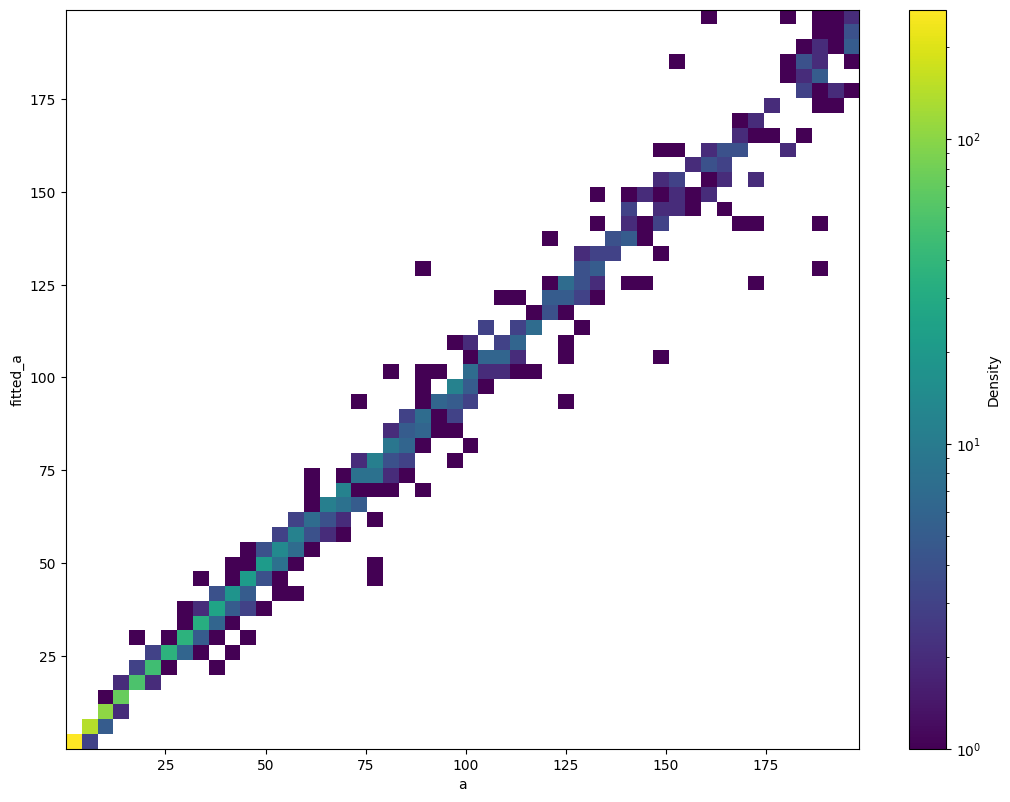

In [8]:
plot_density('a')

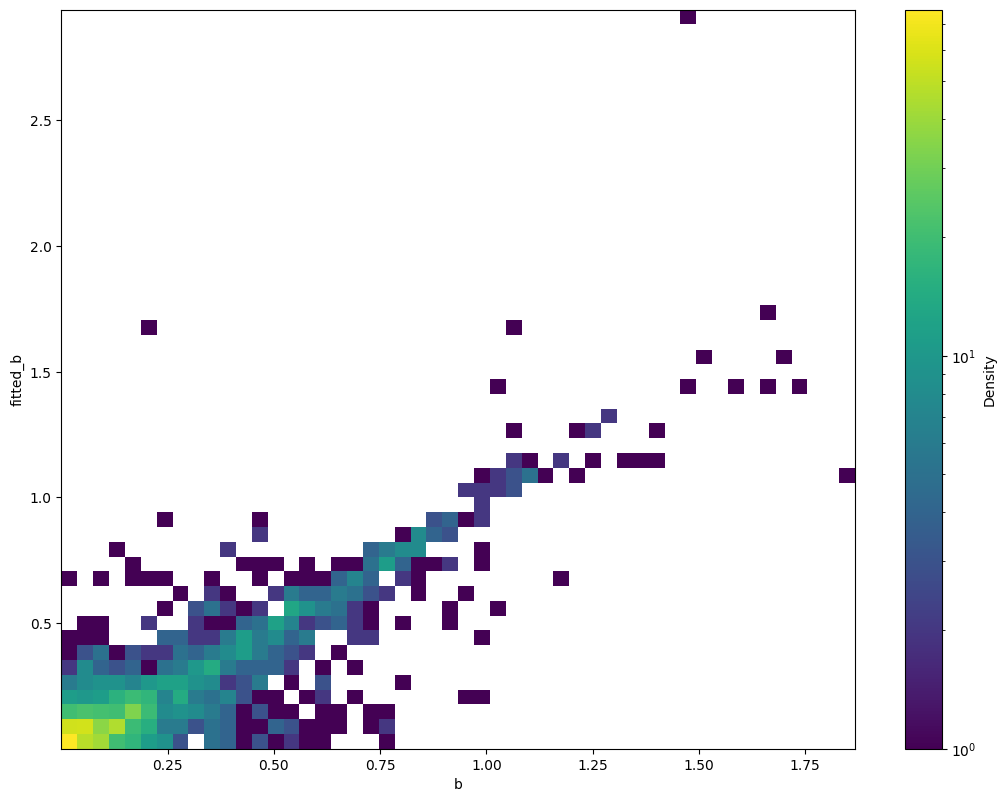

In [9]:
plot_density('b')

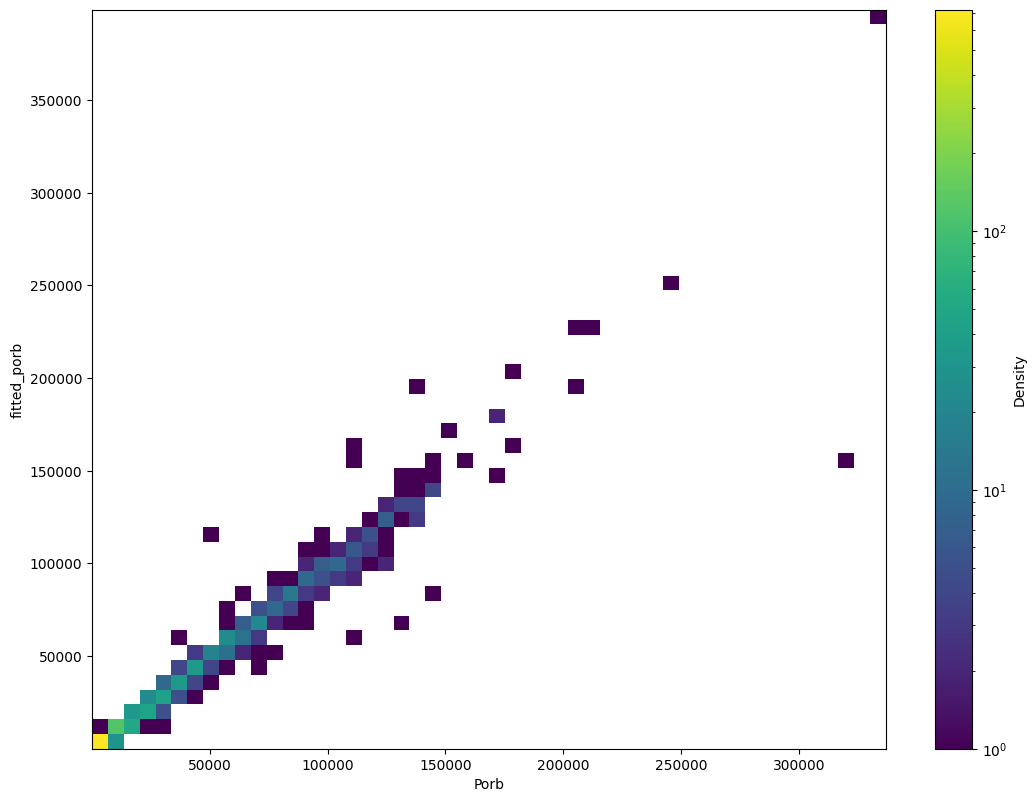

In [10]:
plot_density('Porb')

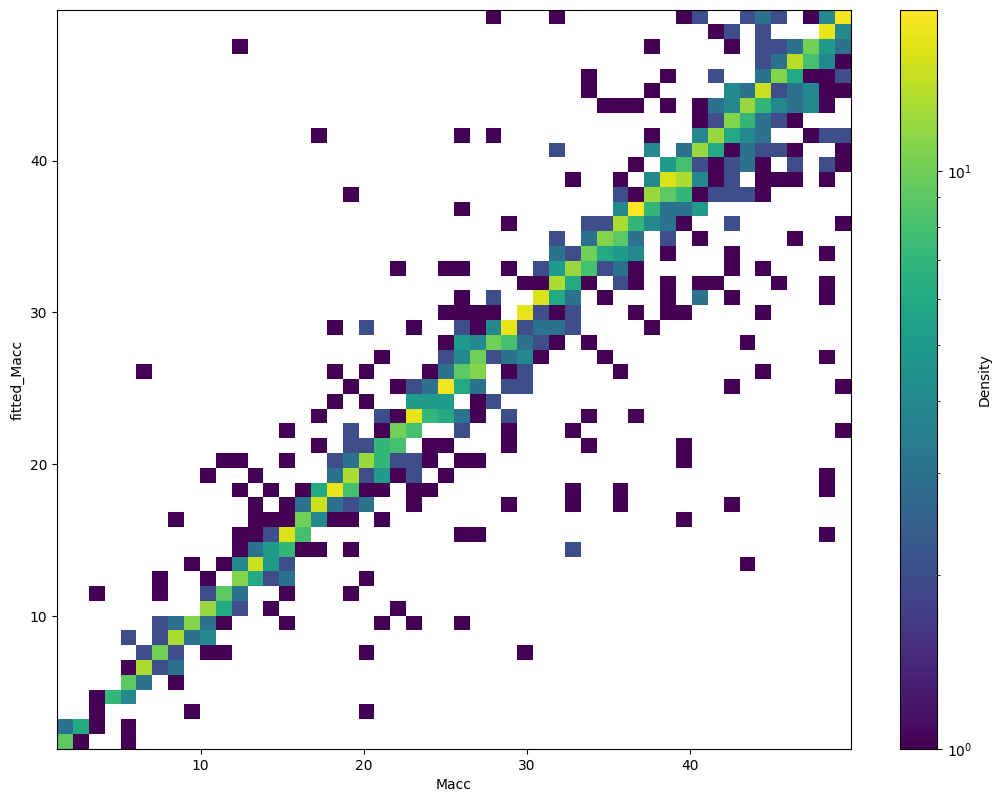

In [11]:
plot_density('Macc')

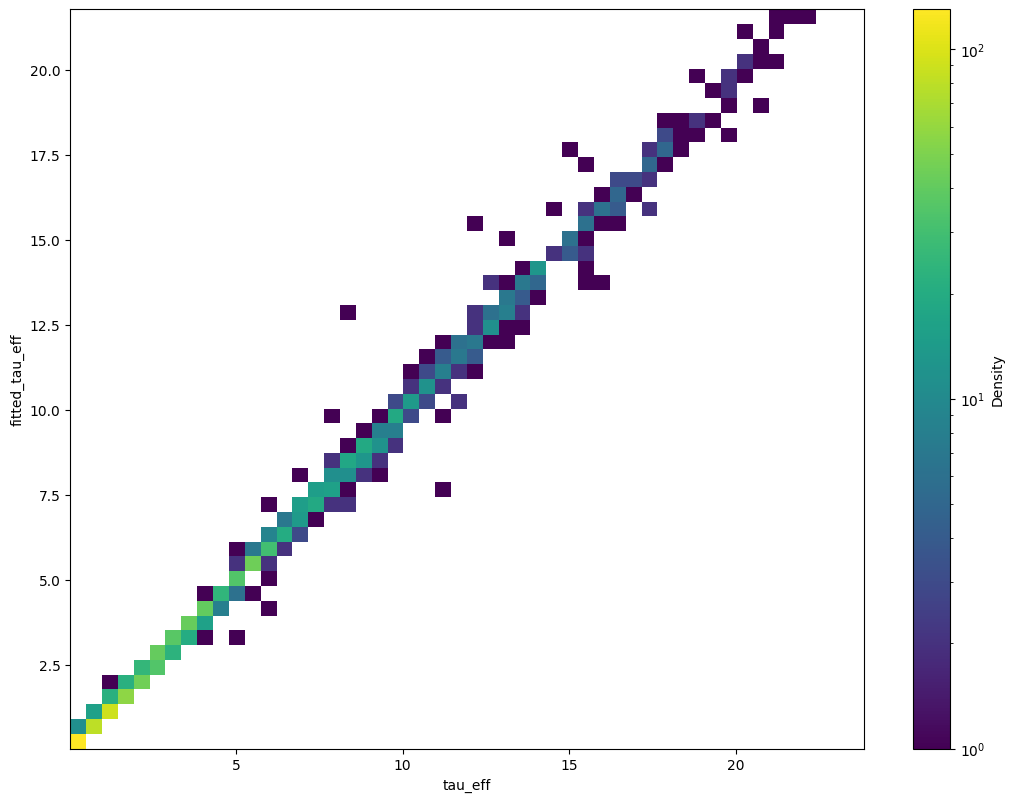

In [12]:
plot_density('tau_eff')

In [13]:
def plot_relation(x, y='RV accuracy', logx=True, logy=True, bins=20):
    for cadence, cadence_group in results.groupby('cadence'):
        baselines = numpy.sort(cadence_group['baseline'].unique())
        fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
        if len(baselines) == 1:
            axes = [axes]
        for ax, baseline in zip(axes, baselines):
            subset = cadence_group[cadence_group['baseline'] == baseline]
            xdata = subset[x]
            ydata = subset[y]
            diff = numpy.abs(subset[x] - subset[params[x]]) / subset[x]
            # Bin edges
            if logx:
                xbins = numpy.logspace(numpy.log10(xdata.min()), numpy.log10(xdata.max()), bins + 1)
            else:
                xbins = numpy.linspace(xdata.min(), xdata.max(), bins + 1)
            if logy:
                ybins = numpy.logspace(numpy.log10(ydata.min()), numpy.log10(ydata.max()), bins + 1)
            else:
                ybins = numpy.linspace(ydata.min(), ydata.max(), bins + 1)
            # Digitize to get bin indices
            xinds = numpy.digitize(xdata, xbins) - 1
            yinds = numpy.digitize(ydata, ybins) - 1
            mean_diff = numpy.full((bins, bins), numpy.nan)
            for i in range(bins):
                for j in range(bins):
                    mask = (xinds == i) & (yinds == j)
                    if numpy.any(mask):
                        mean_diff[i, j] = diff[mask].mean()
            color_norm = pyplot.matplotlib.colors.LogNorm(
                vmin=numpy.nanmin(mean_diff), vmax=numpy.nanmax(mean_diff)
            )
            mesh = ax.pcolormesh(
                xbins, ybins, mean_diff.T,
                cmap='viridis',
                norm=color_norm
            )
            ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
            ax.set_xlabel(x)
            ax.set_ylabel(y)
            if logx:
                ax.set_xscale('log')
            if logy:
                ax.set_yscale('log')
            fig.colorbar(mesh, ax=ax, label='Mean absolute difference (%)')
        pyplot.tight_layout()
        pyplot.show()

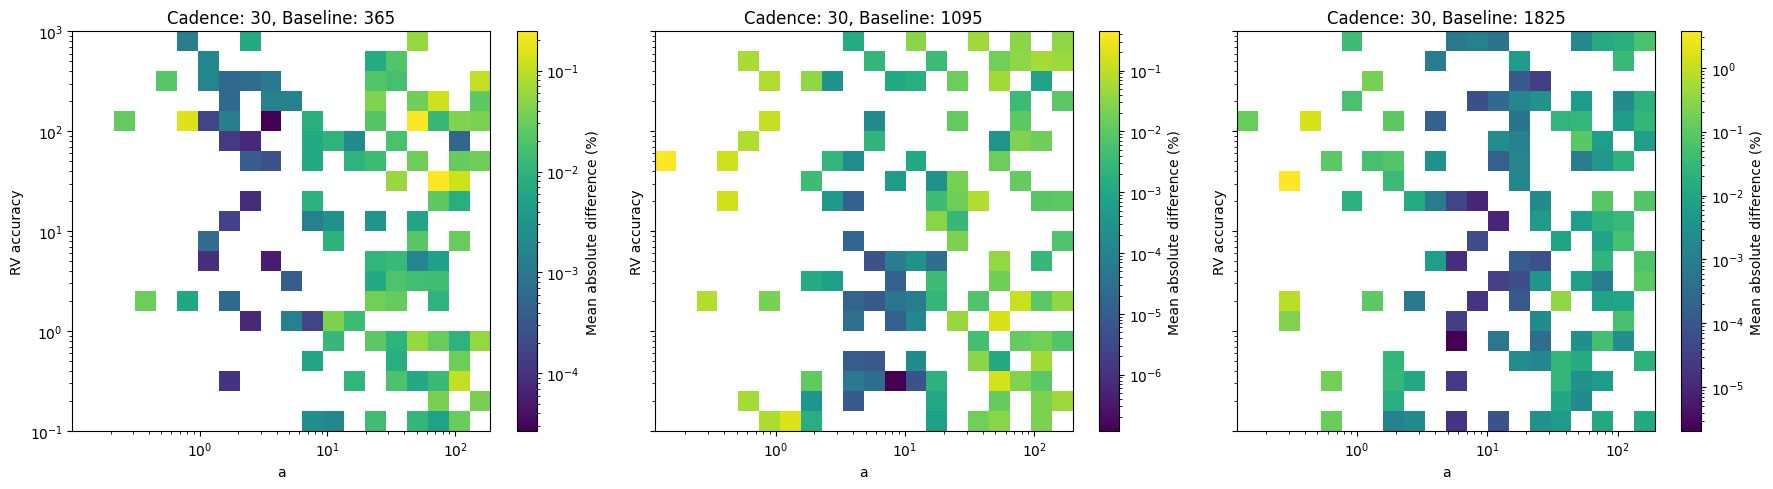

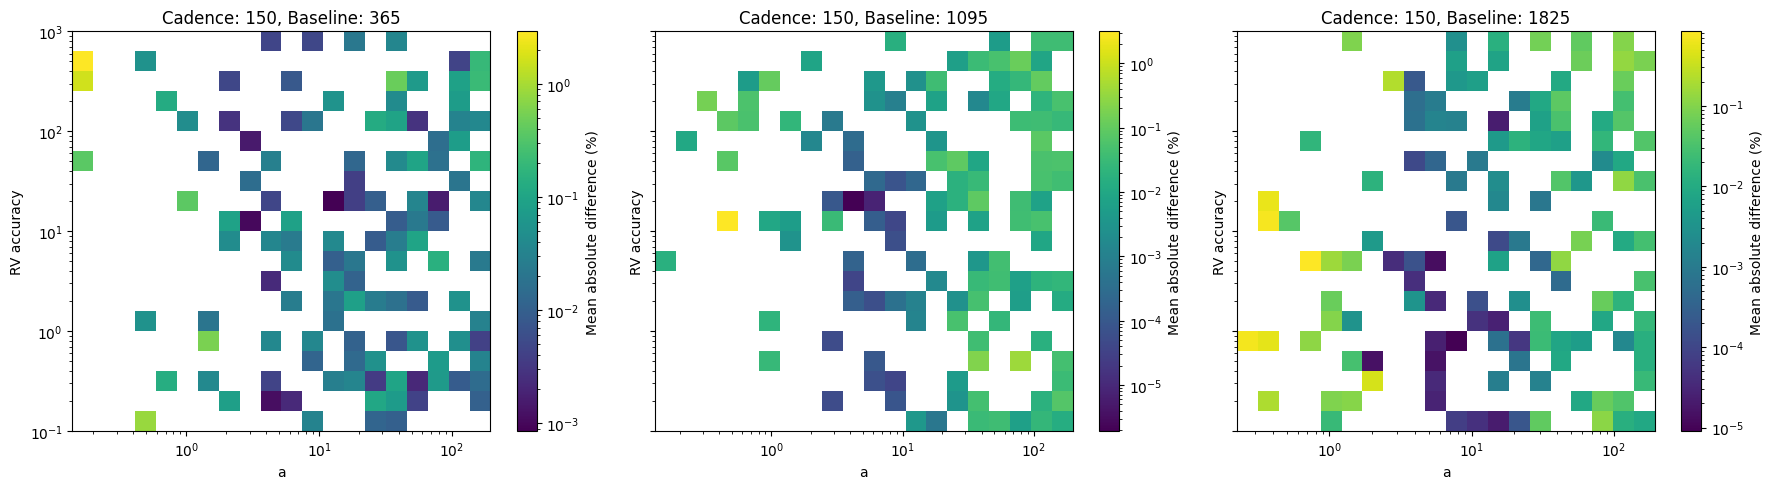

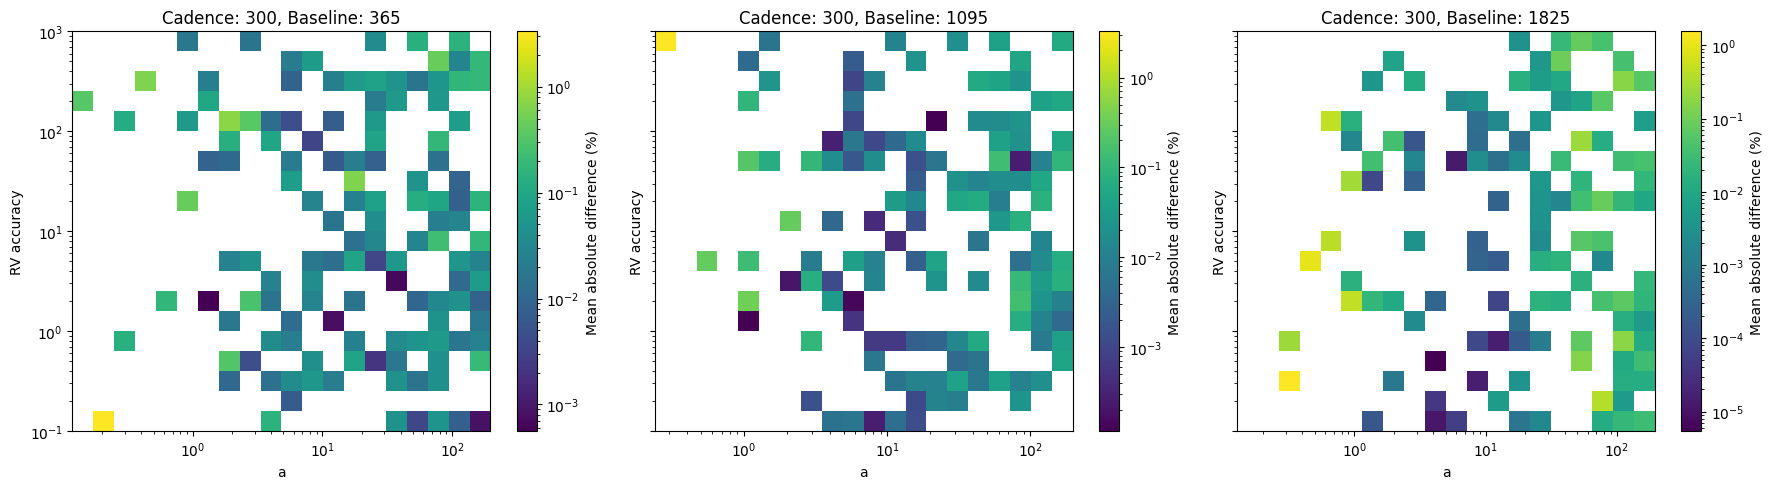

In [14]:
plot_relation('a')

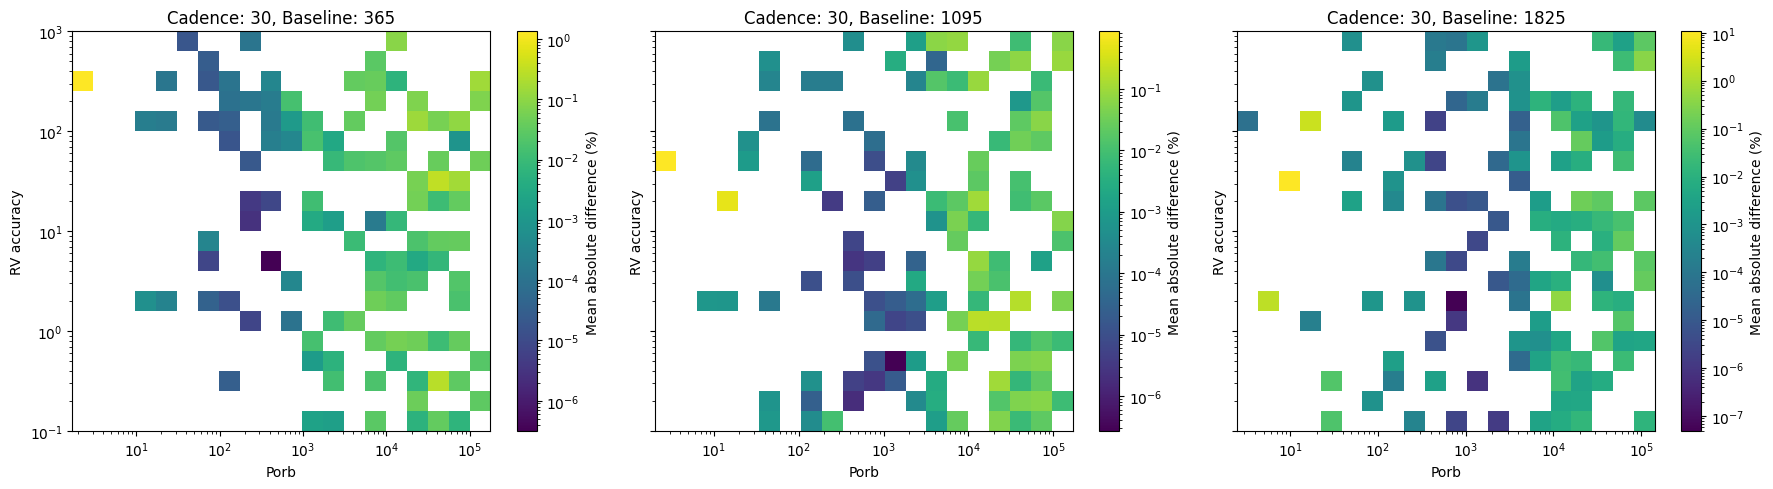

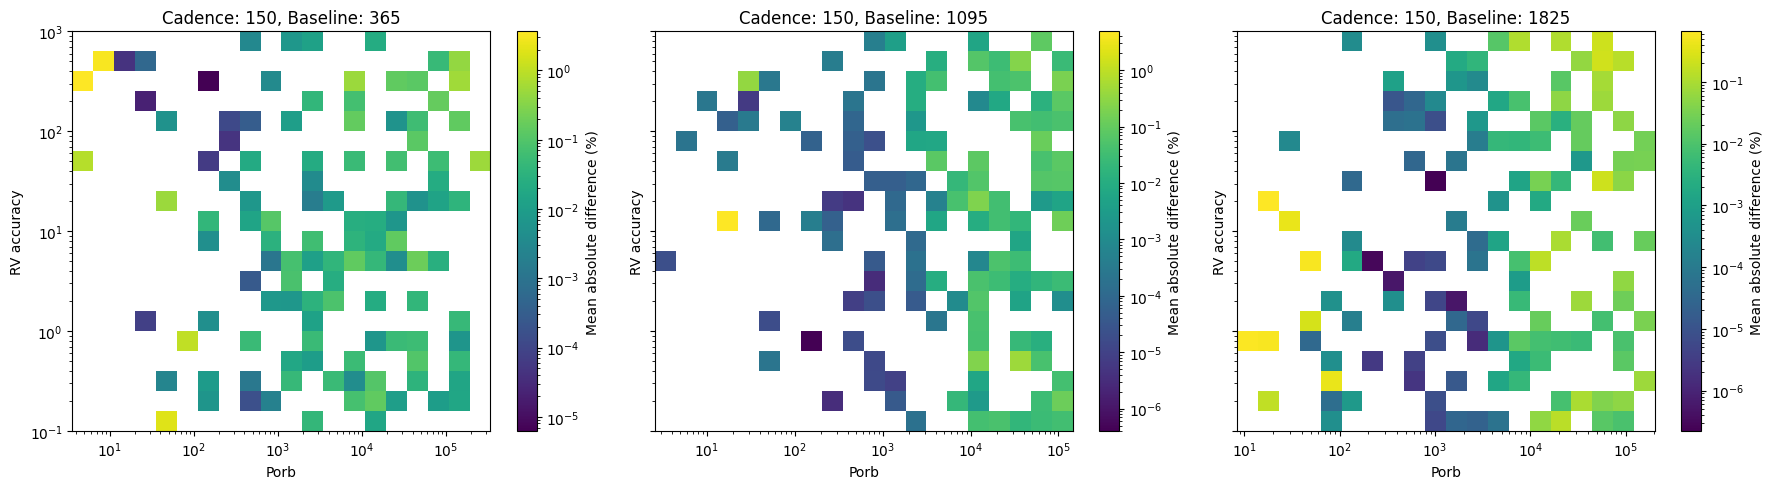

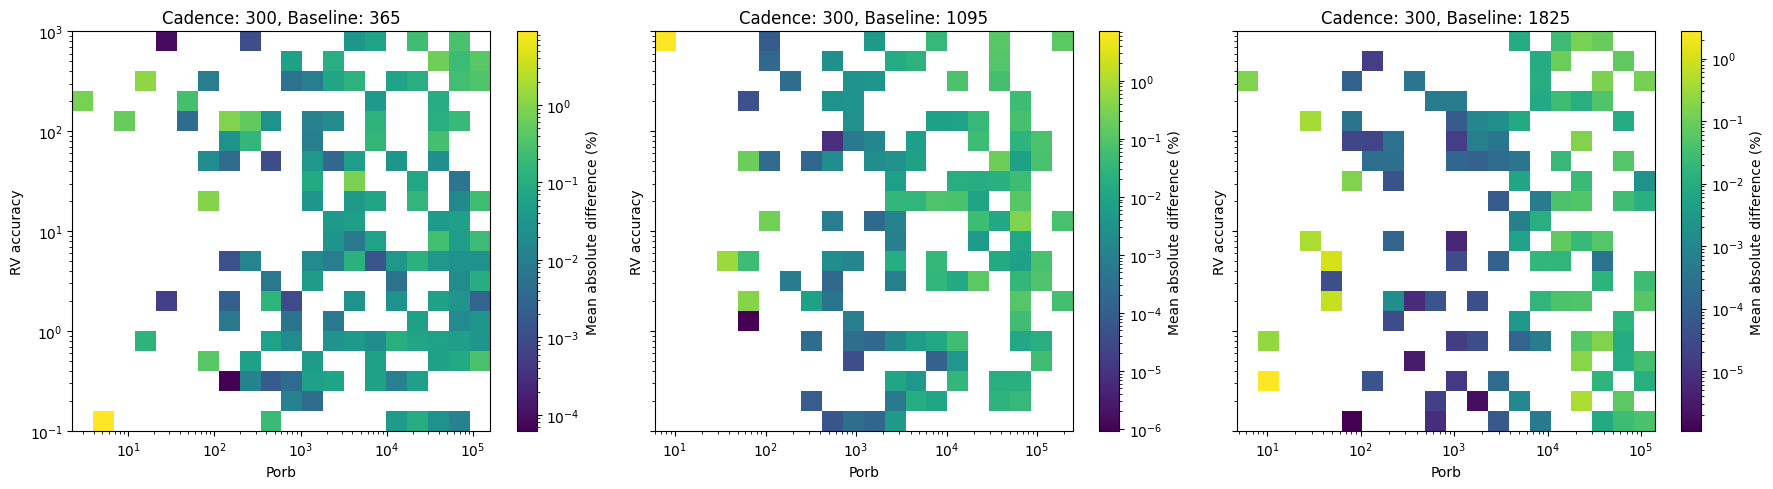

In [15]:
plot_relation('Porb')

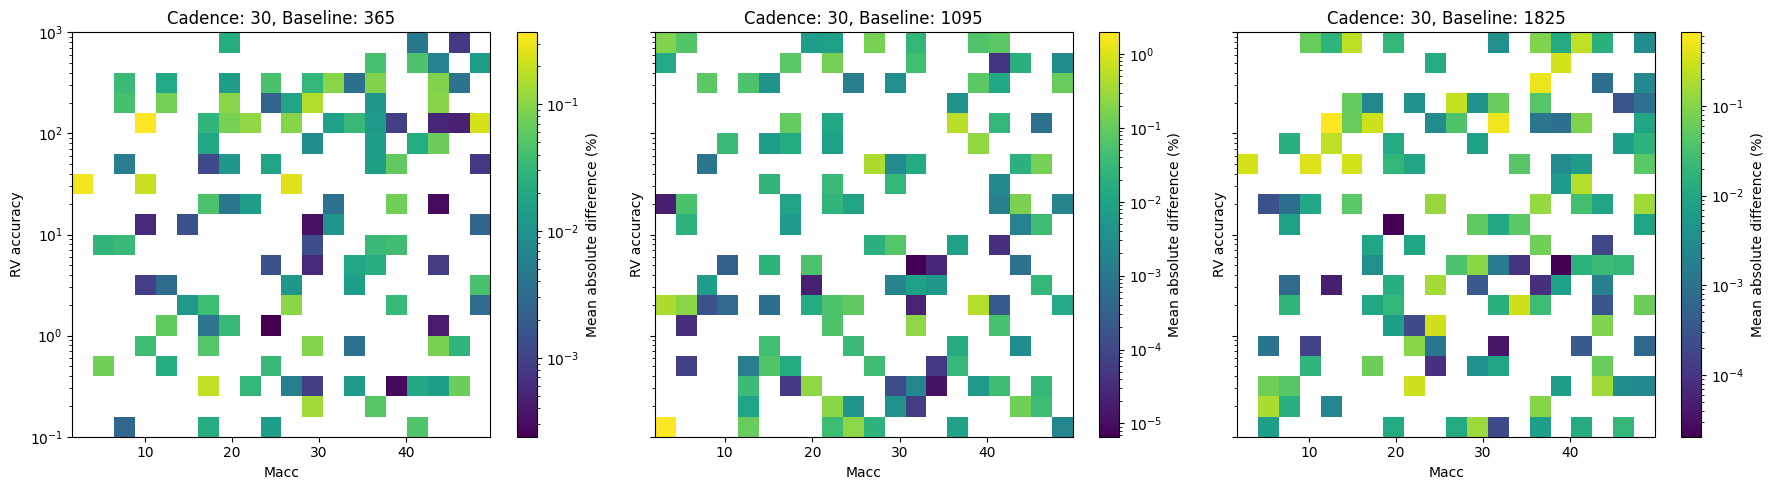

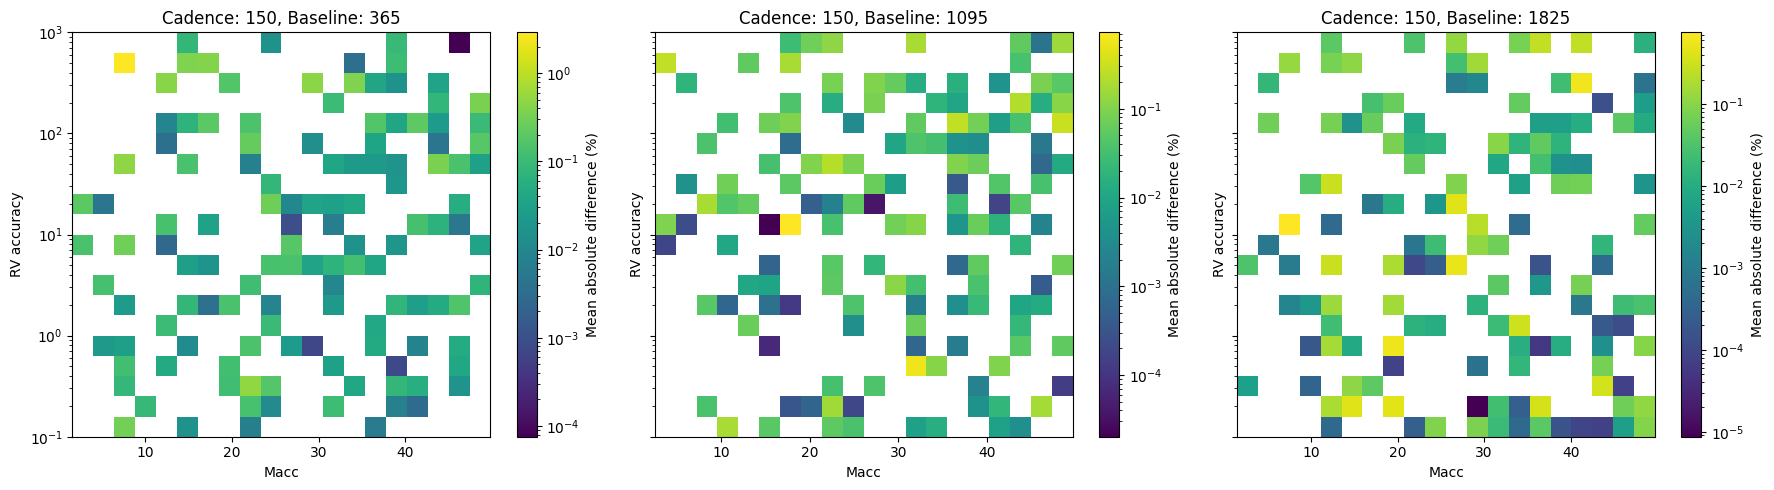

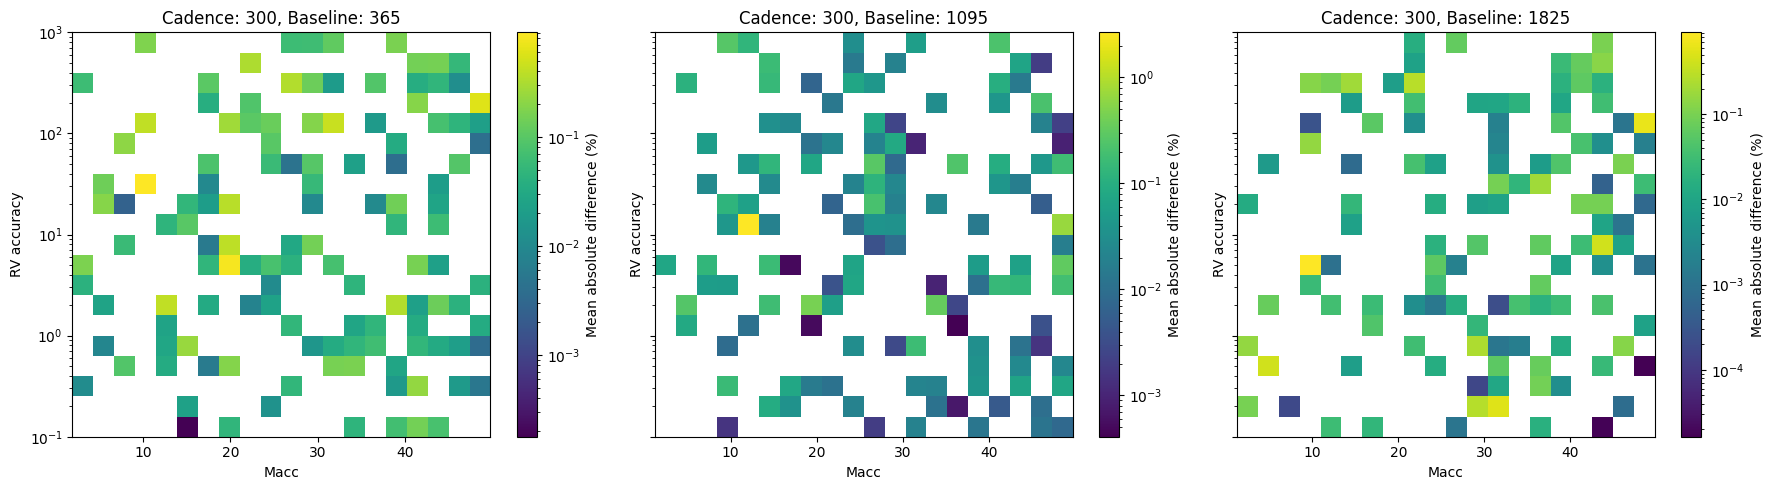

In [16]:
plot_relation('Macc', logx=False)

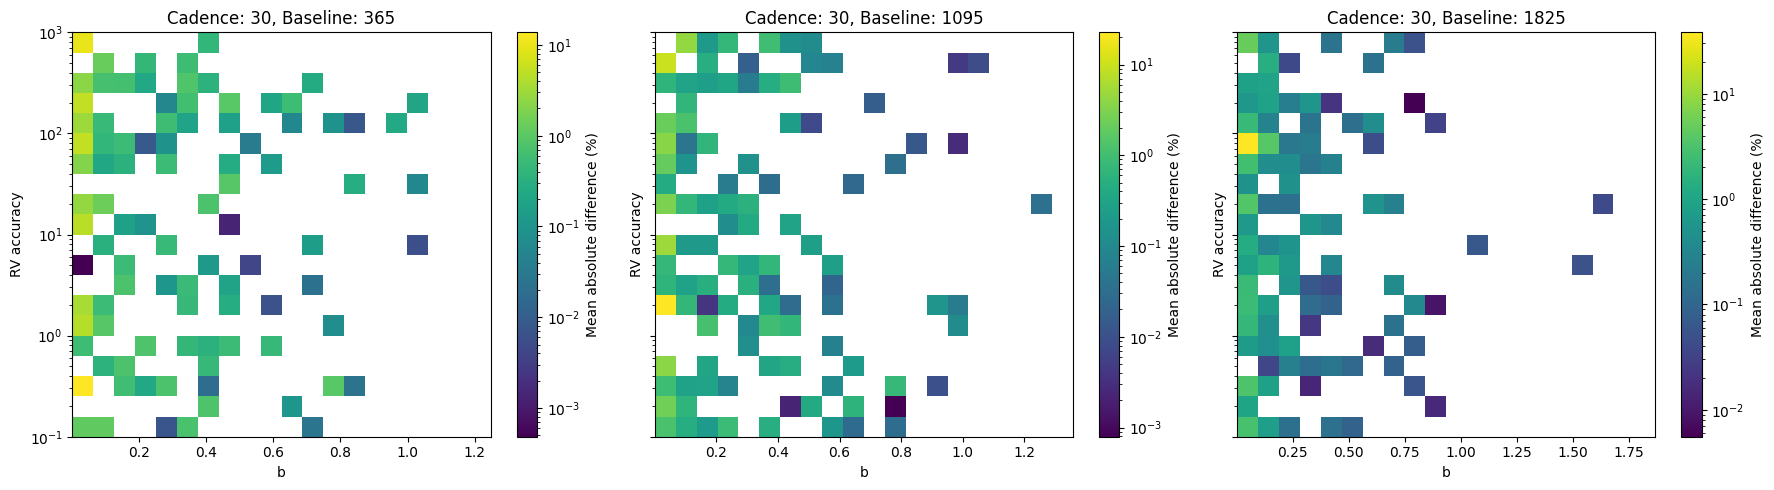

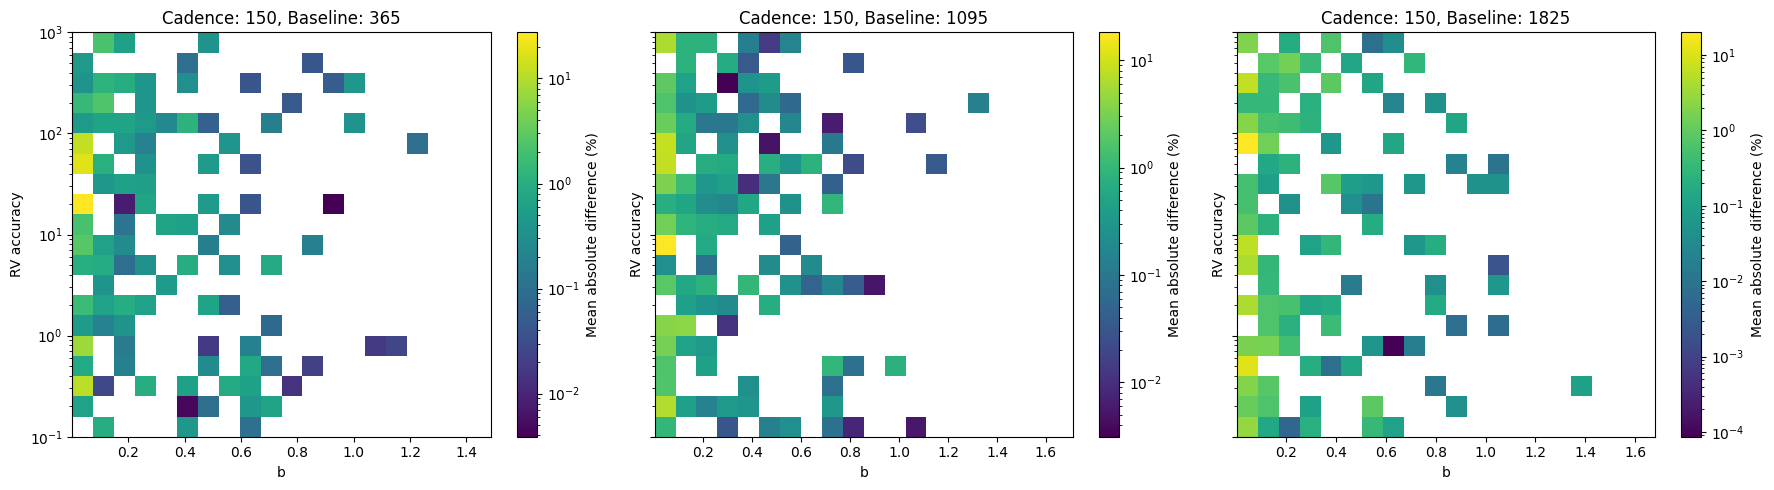

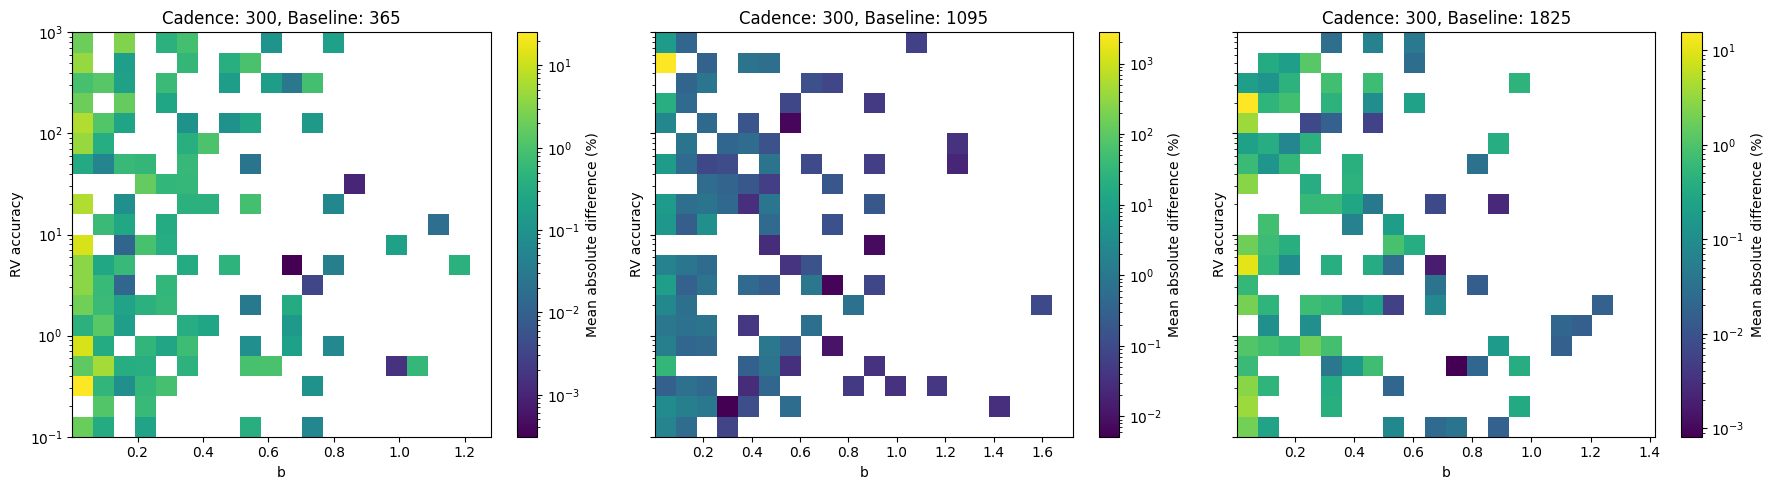

In [17]:
plot_relation('b', logx=False)